# Segmentação semântica e por instância

Comparação no formato da referência: imagem de entrada, máscara semântica (uma classe de objeto) e mapa de instâncias (uma cor por objeto). O primeiro teste usa o recorte da imagem de moedas fornecida; o segundo usa `skimage.data.page()`, uma página impressa.

Dependências: `numpy`, `matplotlib`, `scipy` e `scikit-image`. No Colab, instale com `%pip install scikit-image`.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from skimage import data, feature, filters, io, measure, morphology, transform, util
from skimage.color import label2rgb, rgb2gray

plt.rcParams['figure.figsize'] = (15, 4)

In [2]:
def segmentar(imagem, polaridade, detectar_moedas=False, area_minima=20):
    """Gera máscara semântica e rótulos de instância a partir de uma imagem.

    polaridade='claro' seleciona objetos mais claros que o fundo;
    polaridade='escuro' seleciona objetos mais escuros que o fundo.
    Para moedas, a transformada de Hough detecta círculos; para texto,
    componentes conectados identificam cada região independente.
    """
    if imagem.ndim == 3:
        if imagem.shape[-1] == 4:
            imagem = imagem[..., :3]
        cinza = rgb2gray(imagem)
    else:
        cinza = util.img_as_float(imagem)

    suavizada = filters.gaussian(cinza, sigma=1.0)
    if detectar_moedas:
        # Os círculos da foto têm raios aproximados entre 17 e 30 pixels.
        bordas = feature.canny(suavizada, sigma=2, low_threshold=0.1, high_threshold=0.3)
        raios = np.arange(17, 31, 2)
        acumulador = transform.hough_circle(bordas, raios)
        _, centros_x, centros_y, raios_detectados = transform.hough_circle_peaks(
            acumulador, raios, min_xdistance=30, min_ydistance=30,
            threshold=0.2, total_num_peaks=24
        )
        rotulos = np.zeros(suavizada.shape, dtype=np.int32)
        yy, xx = np.ogrid[:suavizada.shape[0], :suavizada.shape[1]]
        for indice, (centro_x, centro_y, raio) in enumerate(
            zip(centros_x, centros_y, raios_detectados), start=1
        ):
            dentro = (xx - centro_x) ** 2 + (yy - centro_y) ** 2 <= raio ** 2
            rotulos[dentro] = indice
        mascara = rotulos > 0
    else:
        limiar = filters.threshold_otsu(suavizada)
        mascara = suavizada > limiar if polaridade == 'claro' else suavizada < limiar
        mascara = morphology.remove_small_objects(mascara, max_size=area_minima - 1)
        rotulos = measure.label(mascara, connectivity=2)
        # Descarta componentes minúsculos que não representam instâncias úteis.
        areas = np.bincount(rotulos.ravel())
        area_maxima = max(area_minima, int(mascara.size * 0.02))
        manter = (areas >= area_minima) & (areas <= area_maxima)
        manter[0] = False
        mascara = manter[rotulos]
        rotulos = measure.label(mascara, connectivity=2)

    return mascara, rotulos


def plotar_comparacao(imagem, titulo, polaridade, detectar_moedas=False, area_minima=20):
    mascara, rotulos = segmentar(imagem, polaridade, detectar_moedas, area_minima)
    colorida = label2rgb(rotulos, bg_label=0, bg_color=(0, 0, 0))

    fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(titulo, fontsize=15)
    eixos[0].imshow(imagem, cmap='gray' if imagem.ndim == 2 else None)
    eixos[0].set_title('Entrada')
    eixos[1].imshow(mascara, cmap='gray', vmin=0, vmax=1)
    eixos[1].set_title('Semântica (1 classe: objeto)')
    eixos[2].imshow(colorida)
    eixos[2].set_title(f'Instância ({rotulos.max()} objetos)')
    for eixo in eixos:
        eixo.axis('off')
    plt.tight_layout()
    plt.show()
    return mascara, rotulos

## Teste 1 — moedas

A transformada de Hough localiza círculos na imagem; cada círculo detectado vira uma instância colorida. A máscara semântica reúne todas as moedas em uma única classe.

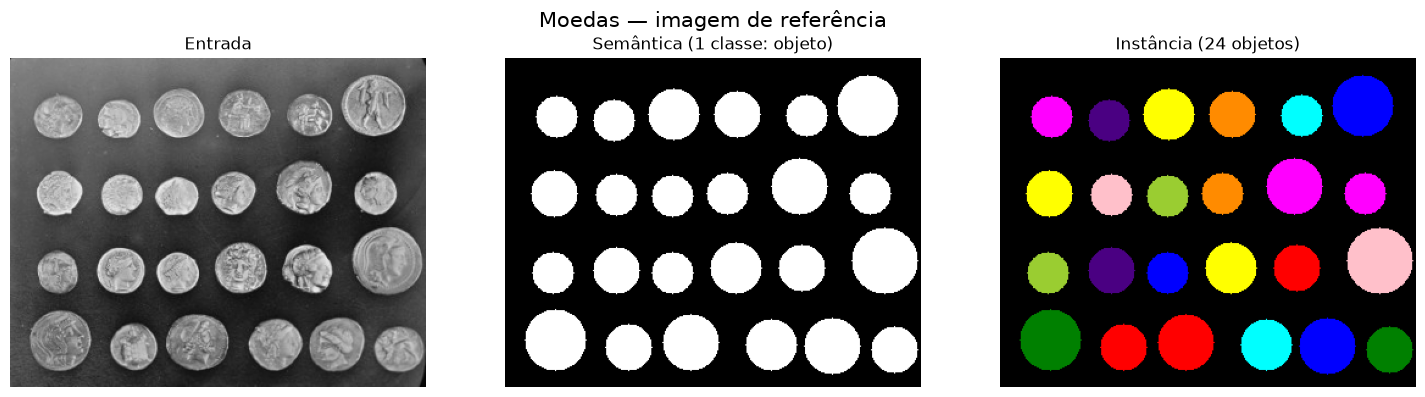

Instâncias encontradas: 24 moedas


In [3]:
imagem_moedas = io.imread('segmentacao_entrada_moedas.png')
mascara_moedas, instancias_moedas = plotar_comparacao(
    imagem_moedas, 'Moedas — imagem de referência',
    polaridade='claro', detectar_moedas=True, area_minima=300
)
print(f'Instâncias encontradas: {instancias_moedas.max()} moedas')

## Teste 2 — página impressa

Na página, os objetos de interesse são os componentes escuros (caracteres/traços). Como eles ficam majoritariamente separados, a rotulagem de componentes conectados já atribui um identificador a cada instância.

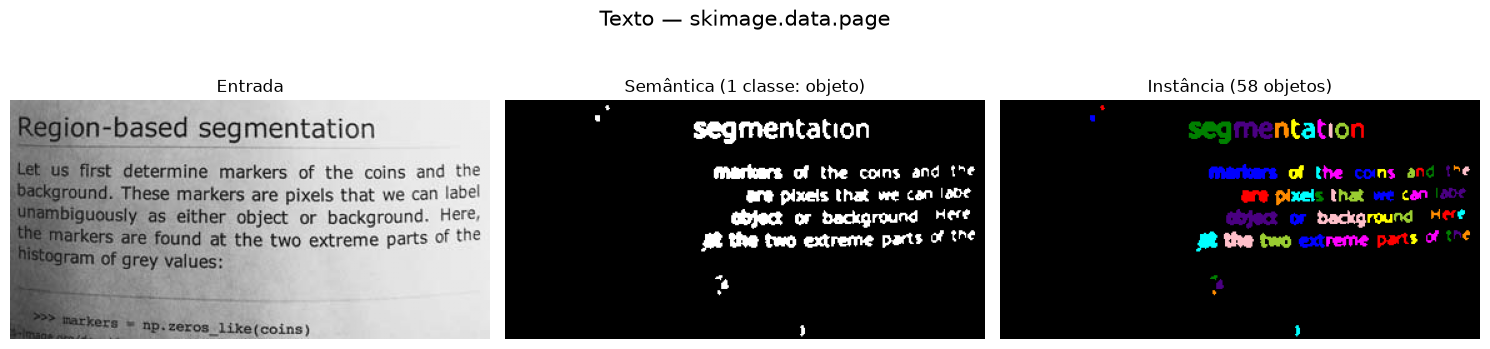

Instâncias encontradas: 58 componentes de texto


In [4]:
imagem_pagina = data.page()
mascara_pagina, instancias_pagina = plotar_comparacao(
    imagem_pagina, 'Texto — skimage.data.page',
    polaridade='escuro', detectar_moedas=False, area_minima=8
)
print(f'Instâncias encontradas: {instancias_pagina.max()} componentes de texto')

## Análise

Em ambas, a máscara semântica marca uma única classe em branco; a máscara por instância dá uma cor a cada objeto. A foto circular permite localizar 24 moedas pela transformada de Hough. Na página, Otsu + componentes conectados detecta 58 regiões de texto, com mais fragmentação por letras e ruído. Portanto, a forma e o contraste da imagem mudam o método e a quantidade de instâncias.